# TP 4 - UC-08 : Analyse des donnees et visualisation
Team **MaxMag** : Maxime DANINO - Awadi BEDJA - Gurvan Godin

**Objectif** : exploiter les donnees Silver et Gold produites au Jour 3 (UC-06) pour calculer les KPI definis
au Jour 1 (UC-01), produire des statistiques, des analyses metier et des visualisations, puis en tirer des
constats sans depasser ce que les donnees permettent d'affirmer.

**Questions metier traitees** (UC-01) : Q1 *quels produits ou categories generent le plus de chiffre d'affaires,
par mois ?* (direction commerciale) et Q3 *comment se situe mon magasin par rapport aux autres ?* (responsable de
magasin).

**Methode** : Spark fait tous les calculs sur les donnees completes ; seuls les petits resultats agreges sont
convertis en tableaux pandas pour etre affiches ou dessines avec Matplotlib.

| Partie | Contenu |
|---|---|
| 0 | Import des bibliotheques et session Spark |
| 1 | Etape 1 : selectionner les donnees |
| 2 | Etape 2 : verifier les KPI |
| 3 | Etape 3 : statistiques descriptives |
| 4 | Etape 4 : analyses metier |
| 5 | Etape 5 : produire des visualisations |
| 6 | Etape 6 : formuler des constats |

In [1]:
import os, sys, platform, subprocess
sys.path.insert(0, os.path.expanduser('~/retail-intelligence/tp4/scripts'))
import pandas as pd, matplotlib, pyspark
from pyspark.sql import functions as F
import parametres as P

pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', ' '))
java = subprocess.run(['java', '-version'], capture_output=True, text=True).stderr.splitlines()[0]
versions = {'Python': platform.python_version(), 'PySpark': pyspark.__version__, 'pandas': pd.__version__,
            'Matplotlib': matplotlib.__version__, 'Java': java}
for k, v in versions.items():
    print(f'{k:<11}: {v}')
with open(os.path.join(P.preuves(1), 'versions.txt'), 'w') as f:
    f.writelines(f'{k}: {v}\n' for k, v in versions.items())

Python     : 3.10.12
PySpark    : 4.2.1
pandas     : 2.3.3
Matplotlib : 3.10.9
Java       : openjdk version "21.0.13.1" 2026-11-17


In [2]:
spark = P.get_spark('TP4-Retail-Intelligence')
print('Spark', spark.version, '|', spark.sparkContext.master, '|', spark.sparkContext.defaultParallelism, 'coeurs')

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/20 13:51:10 WARN Utils: Your hostname, PICOXIA-03, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/20 13:51:10 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/20 13:51:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.1 | local[*] | 16 coeurs


## Etape 1 - Selectionner les donnees

Jeux retenus, tous produits au Jour 3 et stockes dans HDFS (`hdfs://localhost:9000/retail-lake`) :

- **Silver** : `ventes_detaillees`, les ventes nettoyees deja jointes a leurs produits, magasins et dates.
  Elle sert aux statistiques descriptives a la maille la plus fine (l'article de ticket) et au calcul par ticket.
- **Gold** : le modele en etoile (`fait_ventes` et ses 3 dimensions) pour recalculer les KPI, et les deux jeux
  d'indicateurs `kpi_ventes_magasin_mois` et `kpi_ventes_categorie_mois`, qui repondent directement a Q3 et Q1.

Pour chaque jeu, la suite verifie : nom exact, provenance, format, schema, granularite, valeurs vides et
controles qualite disponibles.

In [3]:
jvm, hconf = spark._jvm, spark._jsc.hadoopConfiguration()

def fichiers_hdfs(chemin):
    """Liste recursive des fichiers d'un dossier HDFS : (chemin, taille, date de modification)."""
    p = jvm.org.apache.hadoop.fs.Path(chemin)
    it = p.getFileSystem(hconf).listFiles(p, True)
    out = []
    while it.hasNext():
        s = it.next()
        out.append((s.getPath().toString(), s.getLen(), s.getModificationTime()))
    return out

def format_hdfs(chemin):
    fs = fichiers_hdfs(chemin)
    parquet = [f for f in fs if f[0].endswith('.parquet')]
    succes = [f for f in fs if f[0].endswith('/_SUCCESS')]
    parts = sorted({seg.split('=')[0] for f in parquet for seg in f[0][len(chemin):].split('/') if '=' in seg})
    return {
        'format': 'Parquet (' + ('Snappy' if all('snappy' in f[0] for f in parquet) else 'compression mixte') + ')',
        'fichiers': len(parquet),
        'taille_mo': round(sum(f[1] for f in parquet) / 2**20, 2),   # Mo de 1 048 576 octets, comme au J3
        'partitions': ', '.join(parts) or 'aucune',
        'succes': bool(succes),
        'ecrit_le': pd.to_datetime(max(f[2] for f in succes or parquet), unit='ms', utc=True)
                      .tz_convert('Europe/Paris').strftime('%Y-%m-%d %H:%M'),
    }

DF = {nom: spark.read.parquet(chemin) for nom, (zone, chemin, cle, grain) in P.JEUX.items()}
for nom, df in DF.items():
    print(f'{nom:<32} {len(df.columns):>3} colonnes')

silver/ventes_detaillees          42 colonnes
gold/fait_ventes                  18 colonnes
gold/dim_date                      8 colonnes
gold/dim_produit                   6 colonnes
gold/dim_magasin                   7 colonnes
gold/kpi_ventes_magasin_mois      19 colonnes
gold/kpi_ventes_categorie_mois    15 colonnes


### Provenance : journaux d'execution du Jour 3

Chaque traitement du Jour 3 a ecrit un journal JSON dans `logs/traitements`. On relit le dernier journal
Silver et le dernier journal Gold pour savoir quel script a produit chaque jeu, a partir de quoi, et si les
controles apres ecriture etaient bons.

In [4]:
import json
# Chaque journal est un dossier <nom>.json ecrit par Spark (saveAsTextFile), contenant une seule ligne JSON.
journaux = sorted({f[0].split('/logs/traitements/')[1].split('/')[0] for f in fichiers_hdfs(P.LOGS)})
def lire_journal(prefixe):
    nom = [j for j in journaux if j.startswith(prefixe)][-1]
    texte = ''.join(r.value for r in spark.read.text(f'{P.LOGS}/{nom}').collect())
    return nom, json.loads(texte)

nom_s, js = lire_journal('silver_')
nom_g, jg = lire_journal('gold_')
print('Silver :', nom_s, '|', js['traitement'], '|', js['debut'], '->', js['fin'], '| entree', js['entrees'])
print('Gold   :', nom_g, '|', jg['traitement'], '|', jg['debut'], '->', jg['fin'], '| entree', jg['entree'])

sorties_silver = {s['table']: s for s in js['sorties']}
jeux_gold = {j['jeu']: j for j in jg['jeux']}
s = sorties_silver['ventes_detaillees']
print('\nsilver/ventes_detaillees : relues', s['lignes_relues'], '/ attendues', s['lignes_attendues'],
      '| schema identique', s['schema_identique'], '| cle', s['cle'], 'unique :', s['cle_unique'])
for j in jeux_gold.values():
    if j['jeu'].startswith(('dim_', 'fait_', 'kpi_')):
        print(f"gold/{j['jeu']:<26} ecrites {j['lignes_ecrites']:>7} | relues {j['lignes_relues']:>7} | schema identique {j['schema_identique']}")
    else:   # controles enregistres dans le meme journal (integrite, coherence du CA)
        print(f"controle {j['jeu']:<40} resultat {j['lignes_ecrites']}")

Silver : silver_20261119_112905.json | 06_produire_silver.py | 2026-11-19T11:29:05 -> 2026-11-19T11:30:32 | entree hdfs://localhost:9000/retail-lake/bronze/tpcxbb/<table>/lot=initial|refresh
Gold   : gold_20261119_113357.json | 07_produire_gold.py | 2026-11-19T11:33:57 -> 2026-11-19T11:34:16 | entree hdfs://localhost:9000/retail-lake/silver

silver/ventes_detaillees : relues 674211 / attendues 674211 | schema identique True | cle ligne_id unique : True
gold/dim_date                   ecrites    1826 | relues    1826 | schema identique True
gold/dim_produit                ecrites   18000 | relues   18000 | schema identique True
gold/dim_magasin                ecrites      12 | relues      12 | schema identique True
gold/fait_ventes                ecrites  674211 | relues  674211 | schema identique True
gold/kpi_ventes_magasin_mois    ecrites     720 | relues     720 | schema identique True
gold/kpi_ventes_categorie_mois  ecrites     540 | relues     540 | schema identique True
controle 

### Controles qualite disponibles (rapport de l'etape 9 du Jour 3)

In [5]:
rapports = sorted({f[0].split('/controles/')[1].split('/')[0] for f in fichiers_hdfs(P.CONTROLES) if '/controles_' in f[0]})
rq = spark.read.parquet(f'{P.CONTROLES}/{rapports[-1]}').toPandas()
print('Rapport :', rapports[-1], '|', len(rq), 'controles |', rq['statut'].value_counts().to_dict())
synthese_qualite = (rq.assign(n=1).pivot_table(index='jeu', columns='statut', values='n', aggfunc='sum', fill_value=0))
synthese_qualite

Rapport : controles_20261119_113612 | 49 controles | {'OK': 47, 'ALERTE': 2}


statut,ALERTE,OK
jeu,,
gold/dim_date,0,3
gold/dim_magasin,0,1
gold/dim_produit,0,4
gold/fait_ventes,0,7
gold/kpi_ventes_categorie_mois,0,3
gold/kpi_ventes_magasin_mois,0,2
quality/rejets,0,1
silver -> gold,0,1
silver/date_dim,0,4


### Verification de chaque jeu : volume, granularite, valeurs vides, periode

In [6]:
PROVENANCE = {
    'silver/ventes_detaillees': f"{js['traitement']} ({js['debut'][:16].replace('T', ' ')}), Bronze store_sales + item + store + date_dim, lots initial et refresh",
}
for jeu in ('fait_ventes', 'dim_date', 'dim_produit', 'dim_magasin'):
    PROVENANCE[f'gold/{jeu}'] = f"{jg['traitement']} ({jg['debut'][:16].replace('T', ' ')}), depuis silver"
for jeu in ('kpi_ventes_magasin_mois', 'kpi_ventes_categorie_mois'):
    PROVENANCE[f'gold/{jeu}'] = f"{jg['traitement']} ({jg['debut'][:16].replace('T', ' ')}), depuis fait_ventes et ses dimensions"

USAGE = {
    'silver/ventes_detaillees': 'Statistiques descriptives par ligne et par ticket ; KPI recalcules',
    'gold/fait_ventes': 'Calcul des KPI (CA, quantites, tickets, panier, remise)',
    'gold/dim_date': 'Axe temps des analyses (annee, mois)',
    'gold/dim_produit': 'Axe categorie de produits (Q1)',
    'gold/dim_magasin': 'Axe magasin (Q3)',
    'gold/kpi_ventes_magasin_mois': 'Analyse et visualisation Q3 : comparaison des magasins, evolution',
    'gold/kpi_ventes_categorie_mois': 'Analyse et visualisation Q1 : categories par mois',
}

def controles(nom):
    r = rq[rq['jeu'] == nom]['statut'].value_counts().to_dict()
    if nom == 'silver/ventes_detaillees':
        return 'controles apres ecriture (lignes, schema, cle unique) ; CA identique a Gold (rapport)'
    return ', '.join(f'{v} {k}' for k, v in sorted(r.items())) or 'aucun controle dedie'

lignes = []
for nom, (zone, chemin, cle, grain) in P.JEUX.items():
    df = DF[nom]
    n = df.count()
    distincts = df.select(*cle).distinct().count()
    vides = df.select([F.sum(F.col(c).isNull().cast('int')).alias(c) for c in df.columns]).first().asDict()
    vides = {c: v for c, v in vides.items() if v}
    if 'annee_mois' in df.columns:
        a = df.agg(F.min('annee_mois'), F.max('annee_mois')).first(); periode = f'{a[0]} a {a[1]}'
    elif 'date' in df.columns:
        a = df.agg(F.min('date'), F.max('date')).first(); periode = f'{a[0]} a {a[1]}'
    elif 'annee' in df.columns:
        a = df.agg(F.min('annee'), F.max('annee')).first(); periode = f'{a[0]} a {a[1]}'
    else:
        periode = ''
    ca = df.agg(F.sum('chiffre_affaires')).first()[0] if 'chiffre_affaires' in df.columns else None
    lignes.append({'jeu': nom, 'zone': zone, 'chemin': chemin.replace(P.HDFS, ''), **format_hdfs(chemin),
                   'lignes': n, 'colonnes': len(df.columns), 'granularite': grain, 'cle': ' + '.join(cle),
                   'cle_unique': distincts == n, 'colonnes_avec_vides': ', '.join(f'{c} ({v})' for c, v in vides.items()) or 'aucune',
                   'periode': periode, 'chiffre_affaires': float(ca) if ca is not None else None,
                   'provenance': PROVENANCE[nom], 'controles_qualite': controles(nom), 'usage_prevu': USAGE[nom]})
inventaire = pd.DataFrame(lignes)
inventaire.to_csv(os.path.join(P.preuves(1), 'inventaire_jeux.csv'), index=False, sep=';')
inventaire[['jeu', 'format', 'fichiers', 'taille_mo', 'partitions', 'lignes', 'colonnes', 'cle', 'cle_unique', 'periode']]

,jeu,format,fichiers,taille_mo,partitions,lignes,colonnes,cle,cle_unique,periode
0,silver/ventes_detaillees,Parquet (Snappy),5,88.81,annee,674211,42,ligne_id,True,2001-01 a 2005-12
1,gold/fait_ventes,Parquet (Snappy),5,67.15,annee,674211,18,ligne_id,True,2001 a 2005
2,gold/dim_date,Parquet (Snappy),1,0.02,aucune,1826,8,date_sk,True,2001-01 a 2005-12
3,gold/dim_produit,Parquet (Snappy),1,0.76,aucune,18000,6,produit_sk,True,
4,gold/dim_magasin,Parquet (Snappy),1,0.00,aucune,12,7,magasin_sk,True,
5,gold/kpi_ventes_magasin_mois,Parquet (Snappy),1,0.04,aucune,720,19,magasin_sk + annee_mois,True,2001-01 a 2005-12
6,gold/kpi_ventes_categorie_mois,Parquet (Snappy),1,0.03,aucune,540,15,categorie + annee_mois,True,2001-01 a 2005-12


In [7]:
inventaire[['jeu', 'colonnes_avec_vides', 'chiffre_affaires', 'controles_qualite']]

,jeu,colonnes_avec_vides,chiffre_affaires,controles_qualite
0,silver/ventes_detaillees,promotion_sk (159),1 290 066 342.21,"controles apres ecriture (lignes, schema, cle ..."
1,gold/fait_ventes,promotion_sk (159),1 290 066 342.21,7 OK
2,gold/dim_date,aucune,NaN,3 OK
3,gold/dim_produit,aucune,NaN,4 OK
4,gold/dim_magasin,aucune,NaN,1 OK
5,gold/kpi_ventes_magasin_mois,"ca_meme_mois_n_1 (144), evolution_ca_pct (144)",1 290 066 342.21,2 OK
6,gold/kpi_ventes_categorie_mois,aucune,1 290 066 342.21,3 OK


### Schemas

Les schemas complets sont enregistres dans `UC08_preuves/etape1/schemas.txt`. Affichage du schema de la table
de faits et d'un jeu d'indicateurs :

In [8]:
with open(os.path.join(P.preuves(1), 'schemas.txt'), 'w') as f:
    for nom, df in DF.items():
        f.write(f'== {nom}\n{df._jdf.schema().treeString()}\n')
DF['gold/fait_ventes'].printSchema()
DF['gold/kpi_ventes_magasin_mois'].printSchema()

root
 |-- ligne_id: string (nullable = true)
 |-- ticket: integer (nullable = true)
 |-- date_sk: integer (nullable = true)
 |-- magasin_sk: integer (nullable = true)
 |-- produit_sk: integer (nullable = true)
 |-- promotion_sk: integer (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- montant_catalogue: decimal(7,2) (nullable = true)
 |-- remise: decimal(7,2) (nullable = true)
 |-- chiffre_affaires: decimal(7,2) (nullable = true)
 |-- coupon: decimal(7,2) (nullable = true)
 |-- net_paye: decimal(7,2) (nullable = true)
 |-- taxe: decimal(7,2) (nullable = true)
 |-- cout: decimal(7,2) (nullable = true)
 |-- marge: decimal(7,2) (nullable = true)
 |-- avec_promotion: boolean (nullable = true)
 |-- lot: string (nullable = true)
 |-- annee: integer (nullable = true)

root
 |-- magasin_sk: integer (nullable = true)
 |-- magasin: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- etat: string (nullable = true)
 |-- annee: integer (nullable = true)
 |-- mois: inte

### Coherence entre les jeux

Les jeux Gold sont calcules a partir de Silver : le chiffre d'affaires, les quantites et le nombre de lignes
doivent etre identiques a chaque niveau. Le nombre de tickets n'est additif que par magasin (un ticket = un
magasin), pas par categorie (un ticket contient plusieurs categories).

In [9]:
def totaux(df, tickets=True):
    agg = [F.sum('chiffre_affaires').alias('ca'), F.sum('quantite').alias('quantite')]
    agg.append(F.countDistinct('ticket').alias('tickets') if 'ticket' in df.columns else F.sum('nb_tickets').alias('tickets'))
    agg.append(F.count('*').alias('lignes') if 'ligne_id' in df.columns else F.sum('nb_lignes').alias('lignes'))
    return df.agg(*agg).first().asDict()

coherence = pd.DataFrame({nom: totaux(DF[nom]) for nom in
    ['silver/ventes_detaillees', 'gold/fait_ventes', 'gold/kpi_ventes_magasin_mois', 'gold/kpi_ventes_categorie_mois']}).T
coherence['ca'] = coherence['ca'].astype(float).round(2)
coherence.to_csv(os.path.join(P.preuves(1), 'coherence_jeux.csv'), sep=';')
coherence

,ca,quantite,tickets,lignes
silver/ventes_detaillees,1 290 066 342.21,34089501,90000,674211
gold/fait_ventes,1 290 066 342.21,34089501,90000,674211
gold/kpi_ventes_magasin_mois,1 290 066 342.21,34089501,90000,674211
gold/kpi_ventes_categorie_mois,1 290 066 342.21,34089501,312825,674211


In [10]:
ref = coherence.loc['silver/ventes_detaillees']
for nom, r in coherence.iterrows():
    ecarts = [c for c in ('ca', 'quantite', 'lignes') if r[c] != ref[c]]
    if nom != 'gold/kpi_ventes_categorie_mois' and r['tickets'] != ref['tickets']:
        ecarts.append('tickets')
    print(f"{nom:<32} {'identique a Silver' if not ecarts else 'ECART : ' + ', '.join(ecarts)}")
print('\nTickets distincts :', ref['tickets'], '| somme des tickets par categorie :', coherence.loc['gold/kpi_ventes_categorie_mois', 'tickets'],
      '(plus grand : un ticket compte dans chaque categorie qu il contient)')

silver/ventes_detaillees         identique a Silver
gold/fait_ventes                 identique a Silver
gold/kpi_ventes_magasin_mois     identique a Silver
gold/kpi_ventes_categorie_mois   identique a Silver

Tickets distincts : 90000 | somme des tickets par categorie : 312825 (plus grand : un ticket compte dans chaque categorie qu il contient)


## Etape 2 - Verifier les KPI

On reprend le dictionnaire des KPI du Jour 1 (UC-01, K1 a K8). Pour chaque indicateur : definition, formule,
champs de **nos** jeux Silver et Gold, filtres, granularite, unite et limites. Un KPI n'est retenu que si les
champs necessaires existent dans les donnees preparees au Jour 3.

Adaptation par rapport au Jour 1 : le Jour 3 n'a transforme que les **ventes en magasin**. Les formules du Jour 1
qui additionnaient magasin et web se limitent donc ici au canal magasin.

In [11]:
PERIODE = 'du 01/01/2001 au 31/12/2005, lots initial et refresh reunis (decembre 2005 complet)'
DICO = pd.DataFrame([
    ('K1', "Chiffre d'affaires (CA)", "Montant des ventes apres remise, hors taxe", 'SUM(chiffre_affaires)',
     'chiffre_affaires (= ss_ext_sales_price)', 'aucun ; ventes a prix nul conservees', 'magasin, categorie, mois, annee', 'unite monetaire (dollar probable)',
     'CA brut : retours non deduits ; magasin seulement', 'Retenu'),
    ('K2', 'Quantite vendue', "Nombre d'unites de produits vendues", 'SUM(quantite)',
     'quantite', 'aucun', 'categorie, magasin, mois', 'unites',
     "Additionner des produits differents n'a de sens qu'a l'interieur d'une categorie", 'Retenu'),
    ('K3', 'Nombre de transactions', 'Nombre de passages en caisse (tickets distincts)', 'COUNT(DISTINCT ticket)',
     'ticket (= ss_ticket_number)', 'aucun', 'magasin, mois (un ticket = un magasin, un jour)', 'tickets',
     'Non additif entre categories : un ticket contient plusieurs categories', 'Retenu'),
    ('K4', 'Panier moyen', 'Montant moyen depense par ticket', 'K1 / K3',
     'chiffre_affaires, ticket', 'aucun', 'magasin, mois', 'unite monetaire par ticket',
     'Sensible aux gros tickets : a completer par la mediane ; ne jamais diviser par un nombre de lignes', 'Retenu'),
    ('K5', 'Taux de remise', 'Part du prix catalogue abandonnee en remise', 'SUM(remise) / SUM(montant_catalogue) x 100',
     'remise, montant_catalogue', 'aucun', 'categorie, magasin, mois', '%',
     "Une remise n'est pas forcement liee a une promotion ; correlation n'est pas causalite", 'Retenu'),
    ('K8', 'Evolution du CA', 'Variation du CA par rapport au meme mois de l annee precedente',
     '(K1 mois M - K1 meme mois N-1) / K1 meme mois N-1 x 100',
     'chiffre_affaires, annee, mois', 'periodes completes seulement', 'magasin, categorie, mois ou annee', '%',
     "Pas de valeur pour 2001 (pas d'annee precedente) ; une hausse ne s'explique pas sans autres donnees", 'Retenu'),
    ('K6', 'Taux de retour', 'Part des quantites vendues retournees', 'SUM(sr_return_quantity) / SUM(ss_quantity) x 100',
     'store_returns (absent de Silver et Gold)', '', '', '%',
     "store_returns n'a pas ete nettoye ni transforme au Jour 3", 'Non calculable avec Silver / Gold'),
    ('K7', 'Niveau de stock', "Quantite disponible d'un produit dans un entrepot a une date", 'inv_quantity_on_hand a la date choisie',
     'inventory (absent de Silver et Gold)', '', '', 'unites',
     "inventory n'a pas ete transforme au Jour 3 ; stock connu par entrepot et par semaine seulement", 'Non calculable avec Silver / Gold'),
    ('-', 'Taux de marge', 'Part du CA restant apres le cout des produits', 'SUM(marge) / SUM(chiffre_affaires) x 100',
     'marge, cout (= ss_net_profit, ss_wholesale_cost)', '', 'magasin, categorie, mois', '%',
     "Champs presents mais non qualifies : 74,3 % des lignes ont une marge negative (jeu synthetique)", 'Non retenu (affiche a titre informatif)'),
], columns=['code', 'nom', 'definition', 'formule', 'champs', 'filtres', 'granularite', 'unite', 'limites', 'statut'])
DICO['periode'] = PERIODE
DICO.to_csv(os.path.join(P.preuves(2), 'dictionnaire_kpi.csv'), index=False, sep=';')
DICO[['code', 'nom', 'formule', 'granularite', 'unite', 'statut']]

,code,nom,formule,granularite,unite,statut
0,K1,Chiffre d'affaires (CA),SUM(chiffre_affaires),"magasin, categorie, mois, annee",unite monetaire (dollar probable),Retenu
1,K2,Quantite vendue,SUM(quantite),"categorie, magasin, mois",unites,Retenu
2,K3,Nombre de transactions,COUNT(DISTINCT ticket),"magasin, mois (un ticket = un magasin, un jour)",tickets,Retenu
3,K4,Panier moyen,K1 / K3,"magasin, mois",unite monetaire par ticket,Retenu
4,K5,Taux de remise,SUM(remise) / SUM(montant_catalogue) x 100,"categorie, magasin, mois",%,Retenu
5,K8,Evolution du CA,(K1 mois M - K1 meme mois N-1) / K1 meme mois ...,"magasin, categorie, mois ou annee",%,Retenu
6,K6,Taux de retour,SUM(sr_return_quantity) / SUM(ss_quantity) x 100,,%,Non calculable avec Silver / Gold
7,K7,Niveau de stock,inv_quantity_on_hand a la date choisie,,unites,Non calculable avec Silver / Gold
8,-,Taux de marge,SUM(marge) / SUM(chiffre_affaires) x 100,"magasin, categorie, mois",%,Non retenu (affiche a titre informatif)


### Calcul des KPI retenus sur toute la periode

Calcul a partir de la table de faits Gold `fait_ventes`, sans passer par les jeux d'indicateurs : c'est le calcul
de reference qui servira a controler ces jeux.

In [12]:
fait = DF['gold/fait_ventes']
k = fait.agg(F.sum('chiffre_affaires').alias('K1'), F.sum('quantite').alias('K2'),
             F.countDistinct('ticket').alias('K3'), F.sum('remise').alias('remise'),
             F.sum('montant_catalogue').alias('catalogue'), F.count('*').alias('lignes'),
             F.sum('marge').alias('marge')).first()
K = {'K1 Chiffre d affaires': float(k.K1), 'K2 Quantite vendue': k.K2, 'K3 Nombre de transactions (tickets)': k.K3,
     'K4 Panier moyen': round(float(k.K1) / k.K3, 2), 'K5 Taux de remise (%)': round(100 * float(k.remise) / float(k.catalogue), 2),
     '(non retenu) Taux de marge (%)': round(100 * float(k.marge) / float(k.K1), 2)}
kpi_globaux = pd.DataFrame({'kpi': list(K), 'valeur': list(K.values())})
kpi_globaux.to_csv(os.path.join(P.preuves(2), 'kpi_globaux.csv'), index=False, sep=';')
kpi_globaux

,kpi,valeur
0,K1 Chiffre d affaires,1 290 066 342.21
1,K2 Quantite vendue,34 089 501.00
2,K3 Nombre de transactions (tickets),90 000.00
3,K4 Panier moyen,14 334.07
4,K5 Taux de remise (%),49.98
5,(non retenu) Taux de marge (%),-43.25


### Point de vigilance : lignes, articles et transactions

Le TP demande de ne pas confondre nombre de lignes, nombre d'articles et nombre de transactions. Le calcul ci-dessous
montre l'erreur que l'on commettrait en divisant le CA par le nombre de lignes au lieu du nombre de tickets.

In [13]:
pieges = pd.DataFrame([
    ('Lignes de vente (articles distincts d un ticket)', k.lignes, round(float(k.K1) / k.lignes, 2)),
    ('Articles vendus (somme des quantites)', k.K2, round(float(k.K1) / k.K2, 2)),
    ('Transactions (tickets distincts)', k.K3, round(float(k.K1) / k.K3, 2)),
], columns=['denominateur', 'nombre', 'CA / nombre'])
pieges.to_csv(os.path.join(P.preuves(2), 'lignes_articles_tickets.csv'), index=False, sep=';')
print(f'Lignes par ticket : {k.lignes / k.K3:.2f} | articles par ticket : {k.K2 / k.K3:.1f}')
pieges

Lignes par ticket : 7.49 | articles par ticket : 378.8


,denominateur,nombre,CA / nombre
0,Lignes de vente (articles distincts d un ticket),674211,1 913.45
1,Articles vendus (somme des quantites),34089501,37.84
2,Transactions (tickets distincts),90000,14 334.07


### K8 : evolution annuelle du CA

Le CA d'une annee n'est comparable a celui de l'annee precedente que si les deux annees sont completes. On verifie
d'abord le nombre de jours de vente par annee.

In [14]:
dates = DF['gold/dim_date'].select('date_sk', 'annee', 'mois', 'annee_mois')
par_an = (fait.join(dates.select('date_sk', F.col('annee').alias('a')), 'date_sk')
              .groupBy('a').agg(F.sum('chiffre_affaires').alias('ca'), F.countDistinct('date_sk').alias('jours_de_vente'),
                                F.countDistinct('ticket').alias('tickets'))
              .orderBy('a').toPandas().rename(columns={'a': 'annee'}))
par_an['ca'] = par_an['ca'].astype(float)
par_an['evolution_pct'] = (100 * par_an['ca'].pct_change()).round(2)
par_an.to_csv(os.path.join(P.preuves(2), 'k8_evolution_annuelle.csv'), index=False, sep=';')
par_an

,annee,ca,jours_de_vente,tickets,evolution_pct
0,2001,258 159 395.33,365,17991,NaN
1,2002,256 977 671.52,365,17990,-0.46
2,2003,259 060 054.76,365,17990,0.81
3,2004,260 029 656.73,366,18039,0.37
4,2005,255 839 563.87,365,17990,-1.61


### Controle des jeux d'indicateurs Gold

Les KPI sont recalcules ici par magasin x mois et par categorie x mois, independamment du code du Jour 3, puis
compares aux colonnes des jeux `kpi_ventes_magasin_mois` et `kpi_ventes_categorie_mois`. Tolerance : 0,01 (arrondi
a 2 decimales).

In [15]:
from pyspark.sql import Window
detail = (fait.join(dates.drop('annee'), 'date_sk')
              .join(DF['gold/dim_produit'].select('produit_sk', 'categorie'), 'produit_sk'))

def recalcul(cles):
    r = (detail.groupBy(*cles).agg(F.sum('chiffre_affaires').alias('K1'), F.sum('quantite').alias('K2'),
                                  F.countDistinct('ticket').alias('K3'),
                                  (100 * F.sum('remise') / F.sum('montant_catalogue')).alias('K5'))
               .withColumn('K4', F.col('K1') / F.col('K3')))
    return r

ref_m = recalcul(['magasin_sk', 'annee_mois', 'mois'])
w = Window.partitionBy('magasin_sk', 'mois').orderBy('annee_mois')
ref_m = ref_m.withColumn('K8', 100 * (F.col('K1') - F.lag('K1').over(w)) / F.lag('K1').over(w))
ref_c = recalcul(['categorie', 'annee_mois'])

COLONNES = {'K1': 'chiffre_affaires', 'K2': 'quantite', 'K3': 'nb_tickets', 'K4': 'panier_moyen', 'K5': 'taux_remise', 'K8': 'evolution_ca_pct'}
def comparer(ref, gold, cles, kpis):
    j = ref.join(gold, cles, 'full_outer')
    ligne = {'lignes_recalculees': ref.count(), 'lignes_gold': gold.count(), 'lignes_rapprochees': j.filter(F.col('K1').isNotNull() & F.col('chiffre_affaires').isNotNull()).count()}
    for kk in kpis:
        ecart = F.abs(F.col(kk).cast('double') - F.col(COLONNES[kk]).cast('double'))
        ligne[f'{kk} ecart max'] = j.agg(F.max(ecart)).first()[0]
        ligne[f'{kk} lignes > 0,01'] = j.filter(ecart > 0.01).count()
    return ligne

controle_kpi = pd.DataFrame({
    'kpi_ventes_magasin_mois': comparer(ref_m, DF['gold/kpi_ventes_magasin_mois'], ['magasin_sk', 'annee_mois'], ['K1', 'K2', 'K3', 'K4', 'K5', 'K8']),
    'kpi_ventes_categorie_mois': comparer(ref_c, DF['gold/kpi_ventes_categorie_mois'], ['categorie', 'annee_mois'], ['K1', 'K2', 'K3', 'K4', 'K5']),
}).T
controle_kpi.to_csv(os.path.join(P.preuves(2), 'controle_kpi_gold.csv'), sep=';')
controle_kpi.T

,kpi_ventes_magasin_mois,kpi_ventes_categorie_mois
lignes_recalculees,720.00,540.00
lignes_gold,720.00,540.00
lignes_rapprochees,720.00,540.00
K1 ecart max,0.00,0.00
"K1 lignes > 0,01",0.00,0.00
K2 ecart max,0.00,0.00
"K2 lignes > 0,01",0.00,0.00
K3 ecart max,0.00,0.00
"K3 lignes > 0,01",0.00,0.00
K4 ecart max,0.00,0.01


In [16]:
ecarts = controle_kpi[[c for c in controle_kpi.columns if c.endswith('> 0,01')]].fillna(0).to_numpy().sum()
vides_k8 = ref_m.filter(F.col('K8').isNull()).count()
print('Lignes en ecart de plus de 0,01 :', int(ecarts))
print('K8 sans valeur (annee 2001, pas de N-1) :', vides_k8, '| dans le jeu Gold :',
      DF['gold/kpi_ventes_magasin_mois'].filter(F.col('evolution_ca_pct').isNull()).count())

Lignes en ecart de plus de 0,01 : 0
K8 sans valeur (annee 2001, pas de N-1) : 144 | dans le jeu Gold : 144


## Etape 3 - Statistiques descriptives

Jeu etudie : **silver/ventes_detaillees** (une ligne = un article d'un ticket), complete par une agregation par
ticket. Toutes les statistiques sont calculees par Spark sur les 674 211 lignes ; seuls les tableaux de resultats
passent dans pandas. Les medianes et quartiles sont exacts (fonction `percentile`), pas approches.

Statistiques produites : nombre d'enregistrements, minimum, maximum, moyenne, mediane, quartiles, sommes pour
les mesures additives, repartitions par categorie, par magasin et par jour de la semaine, evolution mensuelle.

In [17]:
ventes = DF['silver/ventes_detaillees']

def stats(df, colonnes, additives):
    """Une ligne par variable : n, min, Q1, mediane, moyenne, Q3, max, ecart-type et somme si la mesure est additive."""
    lignes = []
    for c in colonnes:
        x = F.col(c).cast('double')
        r = df.agg(F.count(x).alias('n'), F.min(x).alias('min'), F.percentile(x, 0.25).alias('q1'),
                   F.percentile(x, 0.5).alias('mediane'), F.avg(x).alias('moyenne'), F.percentile(x, 0.75).alias('q3'),
                   F.max(x).alias('max'), F.stddev(x).alias('ecart_type'), F.sum(F.col(c)).alias('somme')).first().asDict()
        r['somme'] = float(r['somme']) if c in additives else None
        lignes.append({'variable': c, **r})
    return pd.DataFrame(lignes).set_index('variable')

MESURES_LIGNE = ['quantite', 'prix_catalogue_unitaire', 'prix_vente_unitaire', 'montant_catalogue', 'remise', 'chiffre_affaires', 'taux_remise_ligne']
stats_ligne = stats(ventes, MESURES_LIGNE, additives={'quantite', 'montant_catalogue', 'remise', 'chiffre_affaires'})
stats_ligne.round(2)

,n,min,q1,mediane,moyenne,q3,max,ecart_type,somme
variable,,,,,,,,,
quantite,674211,1.00,26.00,51.00,50.56,76.00,100.00,28.88,34 089 501.00
prix_catalogue_unitaire,674211,1.00,37.09,72.85,75.73,109.15,200.00,46.01,NaN
prix_vente_unitaire,674211,0.00,10.24,27.70,37.87,56.78,199.30,34.40,NaN
montant_catalogue,674211,1.20,1 054.94,2 802.96,3 825.72,5 717.86,19 814.00,3 456.59,2 579 339 516.50
remise,674211,0.00,313.18,1 046.90,1 912.27,2 669.73,18 984.00,2 281.96,1 289 273 174.29
chiffre_affaires,674211,0.00,313.56,1 048.35,1 913.45,2 675.06,18 745.00,2 282.14,1 290 066 342.21
taux_remise_ligne,674211,0.00,25.00,50.00,50.00,75.00,100.00,28.86,NaN


### Par ticket

Le panier moyen (K4) est une moyenne : on la compare a la mediane des montants par ticket pour voir si quelques
tres gros tickets la tirent vers le haut.

In [18]:
tickets = (ventes.groupBy('ticket', 'magasin', 'date_vente')
                 .agg(F.sum('chiffre_affaires').alias('montant_ticket'), F.count('*').alias('lignes_par_ticket'),
                      F.sum('quantite').alias('articles_par_ticket'), F.countDistinct('categorie').alias('categories_par_ticket')))
print('Tickets :', tickets.count(), '| tickets sur plusieurs magasins ou plusieurs jours :',
      tickets.groupBy('ticket').count().filter('count > 1').count())
stats_ticket = stats(tickets, ['montant_ticket', 'lignes_par_ticket', 'articles_par_ticket', 'categories_par_ticket'], additives={'montant_ticket'})
stats_ticket.round(2)

Tickets : 90000 | tickets sur plusieurs magasins ou plusieurs jours : 0


,n,min,q1,mediane,moyenne,q3,max,ecart_type,somme
variable,,,,,,,,,
montant_ticket,90000,0.00,6 319.76,13 082.84,14 334.07,20 826.32,84 763.32,9 840.28,1 290 066 342.21
lignes_par_ticket,90000,1.00,4.00,7.00,7.49,11.00,14.00,4.02,NaN
articles_par_ticket,90000,1.00,194.00,372.00,378.77,550.00,1 143.00,217.37,NaN
categories_par_ticket,90000,1.00,2.00,3.00,3.48,5.00,9.00,1.50,NaN


In [19]:
stats_desc = pd.concat([stats_ligne.assign(granularite='ligne de vente'), stats_ticket.assign(granularite='ticket')])
stats_desc.round(4).to_csv(os.path.join(P.preuves(3), 'statistiques.csv'), sep=';')
m = stats_ticket.loc['montant_ticket']
print(f"Panier moyen {m['moyenne']:.2f} | panier median {m['mediane']:.2f} | ecart {100 * (m['moyenne'] - m['mediane']) / m['mediane']:.1f} %")
print('Lignes a prix de vente nul :', ventes.filter(F.col('prix_vente_unitaire') == 0).count(),
      '| tickets de montant nul :', tickets.filter(F.col('montant_ticket') == 0).count())

Panier moyen 14334.07 | panier median 13082.84 | ecart 9.6 %


Lignes a prix de vente nul : 3361 | tickets de montant nul : 37


### Distribution des montants par ticket

Repartition des tickets par tranche de montant (calcul Spark, 10 tranches de 5 000).

In [20]:
tranches = (tickets.withColumn('tranche', F.least(F.floor(F.col('montant_ticket') / 5000), F.lit(9)))
                   .groupBy('tranche').agg(F.count('*').alias('tickets'), F.sum('montant_ticket').alias('ca'))
                   .orderBy('tranche').toPandas())
tranches['tranche'] = [f'{int(t) * 5} a {int(t) * 5 + 5} k' if t < 9 else '45 k et plus' for t in tranches['tranche']]
tranches['part_tickets_pct'] = (100 * tranches['tickets'] / tranches['tickets'].sum()).round(2)
tranches['ca'] = tranches['ca'].astype(float)
tranches.to_csv(os.path.join(P.preuves(3), 'distribution_montant_ticket.csv'), index=False, sep=';')
tranches

,tranche,tickets,ca,part_tickets_pct
0,0 a 5 k,18075,42 061 347.86,20.08
1,5 a 10 k,16728,125 383 779.75,18.59
2,10 a 15 k,16207,201 959 802.37,18.01
3,15 a 20 k,14413,251 103 457.06,16.01
4,20 a 25 k,11030,246 764 361.75,12.26
5,25 a 30 k,7040,192 042 946.31,7.82
6,30 a 35 k,3751,120 845 713.36,4.17
7,35 a 40 k,1711,63 510 925.99,1.90
8,40 a 45 k,707,29 720 327.55,0.79
9,45 k et plus,338,16 673 680.21,0.38


### Repartition par categorie et par magasin

In [21]:
def repartition(cle):
    r = (ventes.groupBy(cle).agg(F.sum('chiffre_affaires').alias('ca'), F.sum('quantite').alias('quantite'),
                                 F.count('*').alias('lignes'), F.countDistinct('ticket').alias('tickets'),
                                 (100 * F.sum('remise') / F.sum('montant_catalogue')).alias('taux_remise'))
               .toPandas())
    r['ca'] = r['ca'].astype(float); r['taux_remise'] = r['taux_remise'].astype(float).round(2)
    r['part_ca_pct'] = (100 * r['ca'] / r['ca'].sum()).round(2)
    return r.sort_values('ca', ascending=False).reset_index(drop=True)

par_categorie = repartition('categorie')
par_categorie.to_csv(os.path.join(P.preuves(3), 'repartition_categorie.csv'), index=False, sep=';')
par_categorie

,categorie,ca,quantite,lignes,tickets,taux_remise,part_ca_pct
0,Music,583 186 372.47,15389404,304206,82177,49.94,45.21
1,Books,344 348 416.31,9108677,179681,72595,50.02,26.69
2,Movies & TV,83 815 845.09,2208104,43754,33568,49.96,6.50
3,Clothing & Accessories,63 296 262.83,1651094,32578,26590,49.62,4.91
4,Electronics,62 242 772.43,1647695,32948,26792,50.21,4.82
5,Home & Kitchen,46 412 354.40,1239862,24653,21112,50.21,3.60
6,Sports & Outdoors,45 872 549.26,1216747,24070,20703,49.77,3.56
7,Toys & Games,30 792 823.20,819874,16306,14801,50.22,2.39
8,Tools & Home Improvement,30 098 946.22,808044,16015,14487,50.61,2.33


In [22]:
par_magasin = repartition('magasin')
par_magasin['panier_moyen'] = (par_magasin['ca'] / par_magasin['tickets']).round(2)
par_magasin.to_csv(os.path.join(P.preuves(3), 'repartition_magasin.csv'), index=False, sep=';')
ecart = (par_magasin['ca'].max() - par_magasin['ca'].min()) / par_magasin['ca'].mean() * 100
print(f'Ecart entre le magasin le plus fort et le plus faible : {ecart:.1f} % du CA moyen par magasin')
par_magasin

Ecart entre le magasin le plus fort et le plus faible : 5.0 % du CA moyen par magasin


,magasin,ca,quantite,lignes,tickets,taux_remise,part_ca_pct,panier_moyen
0,Buffalo,110 808 521.38,2944646,58159,7717,50.13,8.59,14 359.02
1,Forest,108 494 900.14,2861218,56607,7536,49.90,8.41,14 396.88
2,Elmwood,108 493 383.55,2861901,56800,7547,49.98,8.41,14 375.70
3,Germantown,108 421 715.45,2859653,56590,7511,49.86,8.40,14 435.06
4,Williamstown,108 057 440.67,2844862,56185,7480,49.78,8.38,14 446.18
5,Pioneer,107 636 030.27,2828359,55970,7473,49.92,8.34,14 403.32
6,Hillside,107 473 531.09,2845441,56248,7497,50.06,8.33,14 335.54
7,Bedford,106 882 715.89,2815153,55969,7515,49.98,8.29,14 222.58
8,Bloomfield,106 549 916.36,2807267,55108,7357,49.87,8.26,14 482.79
9,Egypt,105 973 488.39,2822398,55773,7454,50.17,8.21,14 217.00


### Repartition par jour de la semaine et evolution mensuelle

In [23]:
ORDRE_JOURS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
par_jour = repartition('jour_semaine')
par_jour['ordre'] = par_jour['jour_semaine'].map({j: i for i, j in enumerate(ORDRE_JOURS)})
par_jour = par_jour.sort_values('ordre').drop(columns='ordre').reset_index(drop=True)
par_jour.to_csv(os.path.join(P.preuves(3), 'repartition_jour_semaine.csv'), index=False, sep=';')
par_jour

,jour_semaine,ca,quantite,lignes,tickets,taux_remise,part_ca_pct
0,Monday,184 527 445.04,4860738,95925,12859,49.91,14.30
1,Tuesday,183 756 503.69,4882214,96644,12860,50.08,14.24
2,Wednesday,185 637 310.67,4889346,96723,12868,49.93,14.39
3,Thursday,184 139 475.79,4891413,96530,12867,50.17,14.27
4,Friday,184 331 371.66,4852157,95856,12860,49.86,14.29
5,Saturday,184 197 392.13,4870342,96415,12858,50.04,14.28
6,Sunday,183 476 843.23,4843291,96118,12828,49.89,14.22


In [24]:
par_mois = (ventes.groupBy('annee_mois', 'annee', 'mois').agg(F.sum('chiffre_affaires').alias('ca'),
                                                               F.countDistinct('ticket').alias('tickets'),
                                                               F.countDistinct('date_vente').alias('jours'))
                 .orderBy('annee_mois').toPandas())
par_mois['ca'] = par_mois['ca'].astype(float)
par_mois['ca_par_jour'] = (par_mois['ca'] / par_mois['jours']).round(2)
par_mois.to_csv(os.path.join(P.preuves(3), 'evolution_mensuelle.csv'), index=False, sep=';')
resume_mois = pd.DataFrame({
    'mois': len(par_mois), 'ca_min': par_mois['ca'].min(), 'mois_min': par_mois.loc[par_mois['ca'].idxmin(), 'annee_mois'],
    'ca_max': par_mois['ca'].max(), 'mois_max': par_mois.loc[par_mois['ca'].idxmax(), 'annee_mois'],
    'ca_moyen': par_mois['ca'].mean(), 'ca_median': par_mois['ca'].median(),
    'ca_par_jour_min': par_mois['ca_par_jour'].min(), 'ca_par_jour_max': par_mois['ca_par_jour'].max()}, index=['CA mensuel'])
resume_mois

,mois,ca_min,mois_min,ca_max,mois_max,ca_moyen,ca_median,ca_par_jour_min,ca_par_jour_max
CA mensuel,60,19 550 669.93,2002-02,22 793 222.53,2003-10,21 501 105.70,21 577 531.29,687 273.44,740 823.78


In [25]:
saison = (par_mois.groupby('mois').agg(ca_moyen=('ca', 'mean'), ca_par_jour_moyen=('ca_par_jour', 'mean')).round(2))
saison['indice_vs_moyenne'] = (100 * saison['ca_par_jour_moyen'] / saison['ca_par_jour_moyen'].mean()).round(1)
saison.to_csv(os.path.join(P.preuves(3), 'saisonnalite_mois.csv'), sep=';')
saison

,ca_moyen,ca_par_jour_moyen,indice_vs_moyenne
mois,,,
1,21 665 053.86,698 872.71,98.90
2,20 044 210.91,710 834.61,100.60
3,21 859 595.74,705 148.25,99.80
4,21 103 880.62,703 462.69,99.60
5,21 780 735.85,702 604.38,99.40
6,21 172 767.25,705 758.91,99.90
7,22 223 816.56,716 897.31,101.50
8,21 858 763.96,705 121.42,99.80
9,21 200 660.90,706 688.70,100.00


## Etape 4 - Analyses metier

Deux analyses, chacune issue d'une question metier du Jour 1 (UC-01) classee « indispensable » :

| Analyse | Question metier | Profil | Jeux utilises |
|---|---|---|---|
| A1 | Q1 : quels produits ou categories generent le plus de chiffre d'affaires, par mois ? | Direction commerciale | kpi_ventes_categorie_mois ; fait_ventes + dim_produit |
| A2 | Q3 : comment se situe mon magasin par rapport aux autres magasins de l'enseigne ? | Responsable de magasin | kpi_ventes_magasin_mois ; dim_magasin |

### A1 - Categories et produits qui generent le plus de chiffre d'affaires, par mois

**Methode** : a partir des 540 lignes categorie x mois, on calcule pour chaque categorie son CA total, sa part
moyenne du CA mensuel, la plage de cette part sur les 60 mois, son rang chaque mois et l'evolution de son CA entre
2001 et 2005. On descend ensuite au niveau produit (fait_ventes) pour mesurer la concentration du CA.

In [26]:
kc = DF['gold/kpi_ventes_categorie_mois']
w_rang = Window.partitionBy('annee_mois').orderBy(F.desc('chiffre_affaires'))
kc_rang = kc.withColumn('rang_mois', F.rank().over(w_rang))
a1 = (kc_rang.groupBy('categorie')
          .agg(F.sum('chiffre_affaires').alias('ca'), F.avg('part_ca_mois_pct').alias('part_moyenne_pct'),
               F.min('part_ca_mois_pct').alias('part_min_pct'), F.max('part_ca_mois_pct').alias('part_max_pct'),
               F.min('rang_mois').alias('meilleur_rang'), F.max('rang_mois').alias('moins_bon_rang'),
               F.sum((F.col('rang_mois') == 1).cast('int')).alias('mois_au_1er_rang'),
               F.sum(F.when(F.col('annee') == 2001, F.col('chiffre_affaires'))).alias('ca_2001'),
               F.sum(F.when(F.col('annee') == 2005, F.col('chiffre_affaires'))).alias('ca_2005'))
          .toPandas())
for c in ['ca', 'part_moyenne_pct', 'part_min_pct', 'part_max_pct', 'ca_2001', 'ca_2005']:
    a1[c] = a1[c].astype(float)
a1['evolution_2005_vs_2001_pct'] = (100 * (a1['ca_2005'] - a1['ca_2001']) / a1['ca_2001']).round(2)
a1['part_ca_total_pct'] = (100 * a1['ca'] / a1['ca'].sum()).round(2)
a1 = a1.sort_values('ca', ascending=False).reset_index(drop=True)
a1.insert(0, 'rang', range(1, len(a1) + 1))
a1.round(2).to_csv(os.path.join(P.preuves(4), 'a1_categories.csv'), index=False, sep=';')
a1[['rang', 'categorie', 'ca', 'part_ca_total_pct', 'part_min_pct', 'part_max_pct', 'meilleur_rang', 'moins_bon_rang', 'mois_au_1er_rang', 'evolution_2005_vs_2001_pct']].round(2)

,rang,categorie,ca,part_ca_total_pct,part_min_pct,part_max_pct,meilleur_rang,moins_bon_rang,mois_au_1er_rang,evolution_2005_vs_2001_pct
0,1,Music,583 186 372.47,45.21,43.51,46.94,1,1,60,-1.57
1,2,Books,344 348 416.31,26.69,24.82,28.39,2,2,0,-0.08
2,3,Movies & TV,83 815 845.09,6.50,5.64,7.57,3,3,0,-3.52
3,4,Clothing & Accessories,63 296 262.83,4.91,3.96,5.74,4,5,0,-0.39
4,5,Electronics,62 242 772.43,4.82,4.08,5.43,4,5,0,1.99
5,6,Home & Kitchen,46 412 354.40,3.60,3.02,4.11,6,7,0,0.90
6,7,Sports & Outdoors,45 872 549.26,3.56,2.60,4.18,6,8,0,0.52
7,8,Toys & Games,30 792 823.20,2.39,1.79,2.95,7,9,0,-1.84
8,9,Tools & Home Improvement,30 098 946.22,2.33,1.69,2.86,8,9,0,-0.87


In [27]:
# Le classement des categories change-t-il d'un mois a l'autre ?
changements = (kc_rang.groupBy('annee_mois').agg(F.collect_list(F.struct('rang_mois', 'categorie')).alias('r'))
                      .toPandas())
ordre = changements['r'].apply(lambda r: tuple(x['categorie'] for x in sorted(r, key=lambda x: x['rang_mois'])))
print('Mois :', len(ordre), '| classements differents des 9 categories :', ordre.nunique())
print('Mois ou le podium (3 premieres) differe de Music, Books, Movies & TV :',
      sum(o[:3] != ('Music', 'Books', 'Movies & TV') for o in ordre))

Mois : 60 | classements differents des 9 categories : 9
Mois ou le podium (3 premieres) differe de Music, Books, Movies & TV : 0


In [28]:
# Niveau produit : concentration du CA
prod = (fait.groupBy('produit_sk').agg(F.sum('chiffre_affaires').alias('ca'), F.sum('quantite').alias('quantite'),
                                       F.countDistinct('ticket').alias('tickets'))
            .join(DF['gold/dim_produit'].select('produit_sk', 'produit_id', 'categorie'), 'produit_sk')
            .toPandas())
prod['ca'] = prod['ca'].astype(float)
prod = prod.sort_values('ca', ascending=False).reset_index(drop=True)
prod['part_pct'] = 100 * prod['ca'] / prod['ca'].sum()
prod['part_cumulee_pct'] = prod['part_pct'].cumsum()
n_vendus = len(prod)
concentration = pd.DataFrame({
    'produits vendus': [n_vendus],
    'part du CA des 10 premiers produits (%)': [prod['part_pct'].head(10).sum()],
    'part du CA des 1 % premiers produits (%)': [prod['part_pct'].head(round(n_vendus / 100)).sum()],
    'produits pour 50 % du CA': [int((prod['part_cumulee_pct'] < 50).sum() + 1)],
    'produits pour 80 % du CA': [int((prod['part_cumulee_pct'] < 80).sum() + 1)],
}).round(2)
concentration['part des produits pour 80 % du CA (%)'] = round(100 * concentration['produits pour 80 % du CA'] / n_vendus, 2)
prod.head(10).round(2).to_csv(os.path.join(P.preuves(4), 'a1_top10_produits.csv'), index=False, sep=';')
concentration.T.to_csv(os.path.join(P.preuves(4), 'a1_concentration_produits.csv'), sep=';')
display(concentration.T)
prod.head(10)[['produit_id', 'categorie', 'ca', 'quantite', 'tickets', 'part_pct']].round(3)

,0
produits vendus,17 856.00
part du CA des 10 premiers produits (%),6.67
part du CA des 1 % premiers produits (%),39.27
produits pour 50 % du CA,1 201.00
produits pour 80 % du CA,9 041.00
part des produits pour 80 % du CA (%),50.63


,produit_id,categorie,ca,quantite,tickets,part_pct
0,AAAAAAAAAAAAAOUQ,Home & Kitchen,17 325 612.37,458983,8614,1.34
1,AAAAAAAAAAAAAOUT,Electronics,16 731 253.00,443846,8347,1.30
2,AAAAAAAAAAAAAOUR,Music,16 183 647.83,423787,7926,1.25
3,AAAAAAAAAAAAAOUS,Music,14 386 162.99,381137,7229,1.11
4,AAAAAAAAAAAAAZXE,Books,3 665 721.02,94634,1853,0.28
5,AAAAAAAAAAAAAPQX,Music,3 642 188.14,91179,1751,0.28
6,AAAAAAAAAAAAAMSV,Clothing & Accessories,3 593 107.69,89600,1739,0.28
7,AAAAAAAAAAAAAIIC,Music,3 511 170.04,95677,1846,0.27
8,AAAAAAAAAAAAADXZ,Music,3 506 665.92,89025,1715,0.27
9,AAAAAAAAAAAAAYLD,Music,3 504 117.99,91755,1786,0.27


In [29]:
# Dans les 10 premiers produits, combien viennent de Music et Books ? Et sur 100 ?
print('Top 10  :', prod.head(10)['categorie'].value_counts().to_dict())
print('Top 100 :', prod.head(100)['categorie'].value_counts().to_dict())
cat_prod = prod.groupby('categorie').agg(produits=('produit_sk', 'count'), ca_moyen_par_produit=('ca', 'mean')).round(2)
cat_prod.to_csv(os.path.join(P.preuves(4), 'a1_produits_par_categorie.csv'), sep=';')
cat_prod.sort_values('ca_moyen_par_produit', ascending=False)

Top 10  : {'Music': 6, 'Home & Kitchen': 1, 'Electronics': 1, 'Books': 1, 'Clothing & Accessories': 1}
Top 100 : {'Music': 43, 'Books': 22, 'Clothing & Accessories': 10, 'Sports & Outdoors': 6, 'Electronics': 5, 'Movies & TV': 5, 'Home & Kitchen': 3, 'Tools & Home Improvement': 3, 'Toys & Games': 3}


,produits,ca_moyen_par_produit
categorie,,
Clothing & Accessories,610,103 764.37
Sports & Outdoors,465,98 650.64
Home & Kitchen,477,97 300.53
Electronics,693,89 816.41
Toys & Games,407,75 658.04
Tools & Home Improvement,410,73 412.06
Music,8156,71 503.97
Movies & TV,1291,64 923.20
Books,5347,64 400.30


**Resultats et interpretation A1**

- Music est la premiere categorie **chaque mois** (60 mois sur 60) et le podium Music, Books, Movies & TV ne change
  jamais. Les parts mensuelles bougent peu (Music entre 43,5 % et 46,9 %).
- Le CA est concentre sur peu de produits : 1 % des produits vendus fait pres de 40 % du CA.
- La domination de Music vient du **nombre de produits** de la categorie (environ 46 % des produits vendus), pas
  d'un CA plus eleve par produit : un produit Music rapporte en moyenne moins qu'un produit Clothing & Accessories.

**Limites** : noms et marques de produits aleatoires (seule la categorie est interpretable) ; retours non deduits ;
la part d'une categorie depend de la taille de son catalogue, qui n'est pas une donnee de vente.

### A2 - Position de chaque magasin par rapport aux autres

**Methode** : a partir des 720 lignes magasin x mois, on calcule pour chaque magasin son CA total, son ecart a la
moyenne des 12 magasins, son rang chaque mois (nombre de mois au premier et au dernier rang), son panier moyen et
son taux de remise. Pour ne pas conclure trop vite qu'un magasin « vend plus », on rapporte aussi le CA a la
surface et au nombre d'employes (dim_magasin).

In [30]:
km = DF['gold/kpi_ventes_magasin_mois']
w_m = Window.partitionBy('annee_mois').orderBy(F.desc('chiffre_affaires'))
km_rang = km.withColumn('rang_mois', F.rank().over(w_m))
a2 = (km_rang.groupBy('magasin_sk', 'magasin', 'ville', 'etat')
          .agg(F.sum('chiffre_affaires').alias('ca'), F.sum('nb_tickets').alias('tickets'),
               F.sum('remise').alias('remise'), F.sum('montant_catalogue').alias('catalogue'),
               F.avg('rang_mois').alias('rang_moyen'),
               F.sum((F.col('rang_mois') == 1).cast('int')).alias('mois_1er'),
               F.sum((F.col('rang_mois') == 12).cast('int')).alias('mois_dernier'),
               F.sum(F.when(F.col('annee') == 2001, F.col('chiffre_affaires'))).alias('ca_2001'),
               F.sum(F.when(F.col('annee') == 2005, F.col('chiffre_affaires'))).alias('ca_2005'))
          .join(DF['gold/dim_magasin'].select('magasin_sk', 'employes', 'surface'), 'magasin_sk')
          .toPandas())
for c in ['ca', 'remise', 'catalogue', 'ca_2001', 'ca_2005']:
    a2[c] = a2[c].astype(float)
a2['ecart_moyenne_pct'] = 100 * (a2['ca'] - a2['ca'].mean()) / a2['ca'].mean()
a2['panier_moyen'] = a2['ca'] / a2['tickets']
a2['taux_remise_pct'] = 100 * a2['remise'] / a2['catalogue']
a2['evolution_2005_vs_2001_pct'] = 100 * (a2['ca_2005'] - a2['ca_2001']) / a2['ca_2001']
a2['ca_par_m2'] = a2['ca'] / a2['surface']
a2['ca_par_employe'] = a2['ca'] / a2['employes']
a2 = a2.sort_values('ca', ascending=False).reset_index(drop=True)
a2.insert(0, 'rang', range(1, len(a2) + 1))
a2.round(2).to_csv(os.path.join(P.preuves(4), 'a2_magasins.csv'), index=False, sep=';')
a2[['rang', 'magasin', 'ville', 'ca', 'ecart_moyenne_pct', 'rang_moyen', 'mois_1er', 'mois_dernier', 'panier_moyen', 'taux_remise_pct', 'evolution_2005_vs_2001_pct']].round(2)

,rang,magasin,ville,ca,ecart_moyenne_pct,rang_moyen,mois_1er,mois_dernier,panier_moyen,taux_remise_pct,evolution_2005_vs_2001_pct
0,1,Buffalo,Lewisburg,110 808 521.38,3.07,5.75,12,4,14 359.02,50.13,-3.51
1,2,Forest,Post Oak,108 494 900.14,0.92,6.28,7,7,14 396.88,49.90,1.56
2,3,Elmwood,Lakeside,108 493 383.55,0.92,6.30,8,4,14 375.70,49.98,0.60
3,4,Germantown,Pierce,108 421 715.45,0.85,6.12,9,6,14 435.06,49.86,7.19
4,5,Williamstown,State Line,108 057 440.67,0.51,6.25,1,5,14 446.18,49.78,-3.28
5,6,Pioneer,Austin,107 636 030.27,0.12,6.25,3,2,14 403.32,49.92,-1.13
6,7,Hillside,Jerusalem,107 473 531.09,-0.03,6.28,3,4,14 335.54,50.06,-3.02
7,8,Bedford,Lyons,106 882 715.89,-0.58,6.65,3,7,14 222.58,49.98,1.25
8,9,Bloomfield,Union Hill,106 549 916.36,-0.89,6.75,4,5,14 482.79,49.87,-4.38
9,10,Egypt,Redland,105 973 488.39,-1.43,7.05,2,5,14 217.00,50.17,-5.99


In [31]:
a2[['rang', 'magasin', 'surface', 'employes', 'ca_par_m2', 'ca_par_employe']].round(2)

,rang,magasin,surface,employes,ca_par_m2,ca_par_employe
0,1,Buffalo,8564004,225,12.94,492 482.32
1,2,Forest,8891512,217,12.20,499 976.50
2,3,Elmwood,7508523,254,14.45,427 139.31
3,4,Germantown,6288915,213,17.24,509 022.14
4,5,Williamstown,8871354,298,12.18,362 608.86
5,6,Pioneer,5777026,221,18.63,487 040.86
6,7,Hillside,8751339,244,12.28,440 465.29
7,8,Bedford,7039717,221,15.18,483 632.20
8,9,Bloomfield,8416754,225,12.66,473 555.18
9,10,Egypt,6942447,215,15.26,492 899.95


In [32]:
# Le classement par CA tient-il quand on rapporte le CA a la taille du magasin ?
a2['rang_ca_par_m2'] = a2['ca_par_m2'].rank(ascending=False).astype(int)
a2['rang_ca_par_employe'] = a2['ca_par_employe'].rank(ascending=False).astype(int)
corr = a2[['ca', 'surface', 'employes', 'tickets']].astype(float).corr().round(3)
corr.to_csv(os.path.join(P.preuves(4), 'a2_correlations.csv'), sep=';')
print('Correlation CA / surface :', corr.loc['ca', 'surface'], '| CA / employes :', corr.loc['ca', 'employes'],
      '| CA / tickets :', corr.loc['ca', 'tickets'], '(12 magasins seulement)')
a2[['magasin', 'rang', 'rang_ca_par_m2', 'rang_ca_par_employe']]

Correlation CA / surface : 0.483 | CA / employes : -0.156 | CA / tickets : 0.826 (12 magasins seulement)


,magasin,rang,rang_ca_par_m2,rang_ca_par_employe
0,Buffalo,1,8,4
1,Forest,2,11,2
2,Elmwood,3,7,9
3,Germantown,4,3,1
4,Williamstown,5,12,12
5,Pioneer,6,1,5
6,Hillside,7,10,8
7,Bedford,8,6,6
8,Bloomfield,9,9,7
9,Egypt,10,5,3


In [33]:
# Le rang mensuel d'un magasin est-il stable ? Exemple du premier et du dernier magasin au total
rangs = km_rang.select('magasin', 'annee_mois', 'rang_mois').toPandas().pivot(index='annee_mois', columns='magasin', values='rang_mois')
rangs.to_csv(os.path.join(P.preuves(4), 'a2_rangs_mensuels.csv'), sep=';')
stab = rangs.agg(['min', 'max', 'mean', 'std']).T.round(2).sort_values('mean')
stab.to_csv(os.path.join(P.preuves(4), 'a2_stabilite_rangs.csv'), sep=';')
stab

,min,max,mean,std
magasin,,,,
Buffalo,1.00,12.00,5.75,3.83
Germantown,1.00,12.00,6.12,3.53
Williamstown,1.00,12.00,6.25,3.42
Pioneer,1.00,12.00,6.25,3.12
Forest,1.00,12.00,6.28,3.75
Hillside,1.00,12.00,6.28,3.19
Elmwood,1.00,12.00,6.30,3.68
Bedford,1.00,12.00,6.65,3.47
Bloomfield,1.00,12.00,6.75,3.19


**Resultats et interpretation A2**

- Les 12 magasins sont tres proches : tous sont a moins de 3,1 % de la moyenne sur cinq ans.
- Le classement mensuel est instable : **chaque magasin a ete au moins un mois premier et au moins un mois
  dernier**. Un mauvais mois ne suffit donc pas a juger un magasin ; il faut regarder plusieurs mois ou l'annee.
- Rapporte a la surface ou au nombre d'employes, le classement change completement (Buffalo, premier en CA, est
  8e en CA par unite de surface). Un CA plus eleve ne prouve pas qu'un magasin est plus performant.

**Limites** : unite de surface non indiquee (valeurs de 5,8 a 8,9 millions) ; seulement 12 magasins, les
correlations sont fragiles ; pas de donnees sur la zone de chalandise, les clients ou les prix locaux.

## Etape 5 - Produire des visualisations

Trois graphiques complementaires, chacun dessine a partir d'un petit tableau deja agrege par Spark :

| Graphique | Question | Type | Pourquoi ce type |
|---|---|---|---|
| G1 | Q1 : quelles categories font le CA ? | Barres horizontales | Comparer 9 categories, noms longs lisibles |
| G2 | Q3 : comment se situe chaque magasin ? | Barres + ligne de reference (moyenne) | Comparer 12 magasins a la moyenne |
| G3 | Comment evoluent les ventes dans le temps ? | Courbe | Evolution sur 60 mois |

Regles appliquees : titre explicite, axes nommes avec leur unite, une seule couleur par graphique (une seule
serie : pas de legende necessaire), source indiquee sous le graphique, grille discrete, pas d'effet 3D.
Les montants sont en **millions d'unites monetaires** (unite non indiquee dans la source, dollar probable).

In [34]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
BLEU, ENCRE, ENCRE2, GRILLE, FOND = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df', '#ffffff'
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': ENCRE2, 'axes.labelcolor': ENCRE, 'xtick.color': ENCRE2,
                     'ytick.color': ENCRE2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': FOND, 'axes.facecolor': FOND, 'axes.titleweight': 'bold'})
millions = mtick.FuncFormatter(lambda x, _: f'{x / 1e6:,.0f}'.replace(',', ' '))

from matplotlib.transforms import blended_transform_factory

def source(ax, texte, y=-0.12):
    """Source sous l'axe des abscisses (y en fraction de la hauteur du graphique)."""
    ax.text(0, y, 'Source : ' + texte + ' - TPCx-BB, donnees synthetiques ; calcul PySpark, equipe MaxMag',
            transform=ax.transAxes, fontsize=8, color=ENCRE2, ha='left', va='top')

def reference(ax, valeur, texte):
    """Ligne de reference horizontale, etiquetee a droite du graphique, hors de la zone des donnees."""
    ax.axhline(valeur, color=ENCRE2, linewidth=1.2, linestyle='--')
    ax.text(1.01, valeur, texte, transform=blended_transform_factory(ax.transAxes, ax.transData),
            ha='left', va='center', fontsize=9, color=ENCRE2)

def pct(v, signe=False):
    if abs(v) < 0.05:
        return '0,0 %'
    return (f'{v:+.1f} %' if signe else f'{v:.1f} %').replace('.', ',')

def enregistrer(fig, nom):
    chemin = os.path.join(P.preuves(5), nom)
    fig.savefig(chemin, dpi=150, bbox_inches='tight')
    print('graphique enregistre :', os.path.relpath(chemin, P.REPO_J4))

### G1 - Chiffre d'affaires par categorie de produits (2001-2005)

graphique enregistre : UC08_preuves/etape5/g1_ca_par_categorie.png


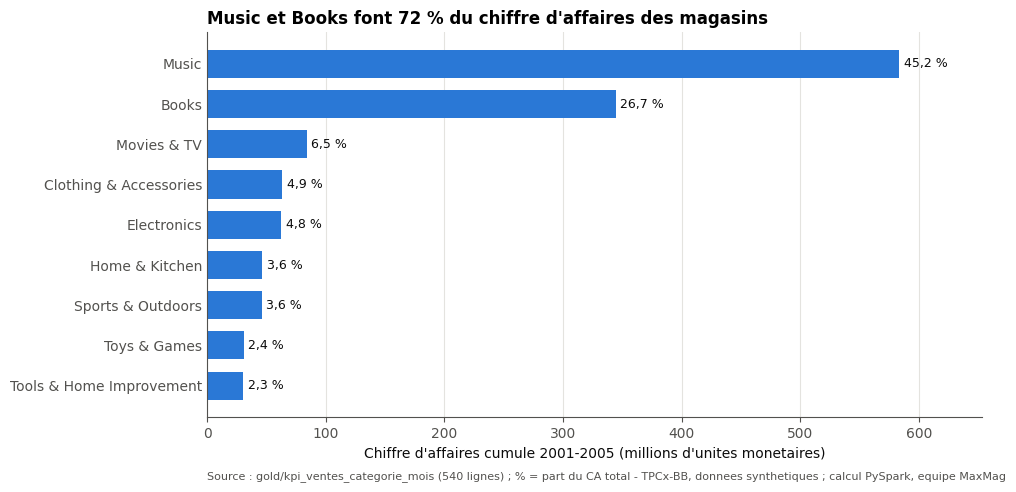

In [35]:
g1 = a1.sort_values('ca')           # tableau de l'analyse A1 : 9 lignes
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(g1['categorie'], g1['ca'], color=BLEU, height=0.7)
for y, (ca, part) in enumerate(zip(g1['ca'], g1['part_ca_total_pct'])):
    ax.text(ca + 4e6, y, pct(part), va='center', fontsize=9, color=ENCRE)
ax.xaxis.set_major_formatter(millions)
ax.set_xlabel("Chiffre d'affaires cumule 2001-2005 (millions d'unites monetaires)")
ax.set_title("Music et Books font 72 % du chiffre d'affaires des magasins", loc='left')
ax.grid(axis='x', color=GRILLE, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(axis='y', length=0)
ax.set_xlim(0, g1['ca'].max() * 1.12)
source(ax, 'gold/kpi_ventes_categorie_mois (540 lignes) ; % = part du CA total', y=-0.14)
enregistrer(fig, 'g1_ca_par_categorie.png'); plt.show()

**Lecture G1** : Music (45,2 %) et Books (26,7 %) dominent ; les sept autres categories pesent chacune moins de
7 %. Ce classement est le meme chaque mois (analyse A1). Limite : la part d'une categorie suit la taille de son
catalogue (Music compte environ 46 % des produits vendus) ; ce n'est pas une mesure de l'attractivite d'un produit.

### G2 - Chiffre d'affaires par magasin compare a la moyenne (2001-2005)

graphique enregistre : UC08_preuves/etape5/g2_ca_par_magasin.png


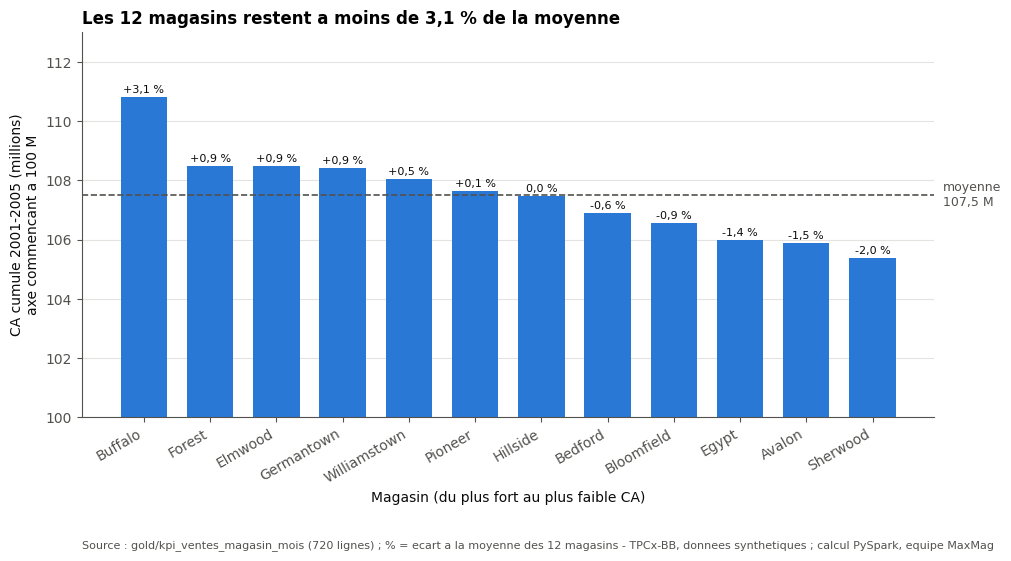

In [36]:
g2 = a2.sort_values('ca', ascending=False)
moyenne = g2['ca'].mean()
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(g2['magasin'], g2['ca'], color=BLEU, width=0.7)
reference(ax, moyenne, f'moyenne\n{moyenne / 1e6:.1f} M'.replace('.', ','))
for x, (ca, e) in enumerate(zip(g2['ca'], g2['ecart_moyenne_pct'])):
    ax.text(x, ca + 0.15e6, pct(e, signe=True), ha='center', fontsize=8, color=ENCRE)
ax.set_ylim(100e6, g2['ca'].max() * 1.02)     # axe tronque, signale dans le titre de l'axe
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x / 1e6:.0f}'))
ax.set_ylabel("CA cumule 2001-2005 (millions)\naxe commencant a 100 M")
ax.set_xlabel('Magasin (du plus fort au plus faible CA)')
ax.set_title('Les 12 magasins restent a moins de 3,1 % de la moyenne', loc='left')
ax.grid(axis='y', color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
source(ax, 'gold/kpi_ventes_magasin_mois (720 lignes) ; % = ecart a la moyenne des 12 magasins', y=-0.32)
enregistrer(fig, 'g2_ca_par_magasin.png'); plt.show()

**Lecture G2** : l'axe vertical commence a 100 millions pour rendre visibles des ecarts faibles : les barres
ne sont donc pas proportionnelles au CA, seuls les pourcentages au-dessus des barres doivent etre lus. Buffalo
depasse la moyenne de 3,1 %, Sherwood est 2,0 % en dessous. Limite : CA brut, non rapporte a la taille du magasin
(le classement change par unite de surface, analyse A2).

### G3 - Evolution mensuelle du chiffre d'affaires (janvier 2001 a decembre 2005)

Les mois n'ont pas tous le meme nombre de jours : la courbe montre le **CA moyen par jour de vente** de chaque
mois, pour qu'un mois de fevrier ne paraisse pas faible seulement parce qu'il est court.

graphique enregistre : UC08_preuves/etape5/g3_evolution_ca_mensuel.png


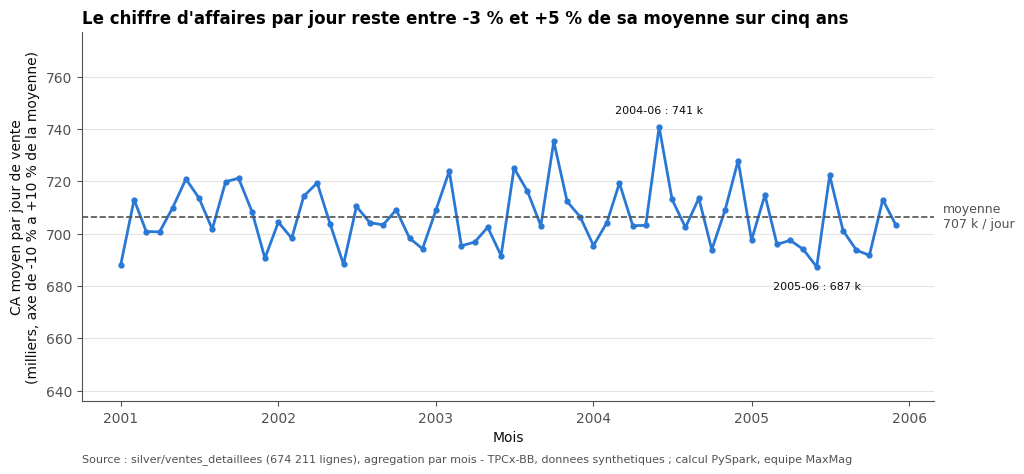

Ecart du mois le plus faible et du plus fort a la moyenne : -2.7 % / +4.9 %


In [37]:
g3 = par_mois.copy()          # tableau de l'etape 3 : 60 lignes
g3['date'] = pd.to_datetime(g3['annee_mois'] + '-01')
moy_j = g3['ca_par_jour'].mean()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(g3['date'], g3['ca_par_jour'], color=BLEU, linewidth=2, marker='o', markersize=3.5)
reference(ax, moy_j, f'moyenne\n{moy_j / 1e3:.0f} k / jour')
for i in (g3['ca_par_jour'].idxmin(), g3['ca_par_jour'].idxmax()):
    r = g3.loc[i]
    ax.annotate(f"{r['annee_mois']} : {r['ca_par_jour'] / 1e3:.0f} k", (r['date'], r['ca_par_jour']),
                xytext=(0, 10 if i == g3['ca_par_jour'].idxmax() else -16), textcoords='offset points',
                ha='center', fontsize=8, color=ENCRE)
ax.set_ylim(moy_j * 0.9, moy_j * 1.1)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x / 1e3:.0f}'))
ax.set_ylabel('CA moyen par jour de vente\n(milliers, axe de -10 % a +10 % de la moyenne)')
ax.set_xlabel('Mois')
ax.set_title("Le chiffre d'affaires par jour reste entre -3 % et +5 % de sa moyenne sur cinq ans", loc='left')
ax.grid(axis='y', color=GRILLE, linewidth=0.8); ax.set_axisbelow(True)
source(ax, 'silver/ventes_detaillees (674 211 lignes), agregation par mois', y=-0.14)
enregistrer(fig, 'g3_evolution_ca_mensuel.png'); plt.show()
print(f"Ecart du mois le plus faible et du plus fort a la moyenne : {100 * (g3['ca_par_jour'].min() / moy_j - 1):.1f} % / {100 * (g3['ca_par_jour'].max() / moy_j - 1):+.1f} %")

**Lecture G3** : aucune tendance ni saisonnalite nette : le CA par jour oscille autour de sa moyenne sans pic
de fin d'annee. Limite : jeu synthetique ; une vraie enseigne montrerait en general un pic en decembre.

## Etape 6 - Formuler des constats

Chaque constat distingue le **resultat observe** (mesure dans les etapes 2 a 5), son **interpretation possible**,
la **limite** de l'analyse et une **recommandation**. Une correlation ne demontre pas une causalite, et les donnees
TPCx-BB sont synthetiques : ces constats valident une demarche, ils ne decrivent pas une enseigne reelle.

In [38]:
# Rappel des chiffres sur lesquels s'appuient les constats (recalcules, pas recopies)
appui = {
    'part CA Music + Books (%)': round(a1.loc[a1['categorie'].isin(['Music', 'Books']), 'part_ca_total_pct'].sum(), 2),
    'mois ou Music est 1re (sur 60)': int(a1.loc[a1['categorie'] == 'Music', 'mois_au_1er_rang'].iloc[0]),
    'part du CA des 1 % premiers produits (%)': round(float(concentration['part du CA des 1 % premiers produits (%)'].iloc[0]), 2),
    'ecart max d un magasin a la moyenne (%)': round(a2['ecart_moyenne_pct'].abs().max(), 2),
    'magasins passes au 1er ET au dernier rang (sur 12)': int(((stab['min'] == 1) & (stab['max'] == 12)).sum()),
    'panier moyen / panier median': f"{stats_ticket.loc['montant_ticket', 'moyenne']:.2f} / {stats_ticket.loc['montant_ticket', 'mediane']:.2f}",
    'indice de saisonnalite min et max': f"{saison['indice_vs_moyenne'].min()} et {saison['indice_vs_moyenne'].max()}",
}
pd.Series(appui, name='valeur').to_frame()

,valeur
part CA Music + Books (%),71.90
mois ou Music est 1re (sur 60),60
part du CA des 1 % premiers produits (%),39.27
ecart max d un magasin a la moyenne (%),3.07
magasins passes au 1er ET au dernier rang (sur 12),12
panier moyen / panier median,14334.07 / 13082.84
indice de saisonnalite min et max,98.9 et 101.5


In [39]:
CONSTATS = pd.DataFrame([
    ('C1', 'Concentration sur deux categories',
     f"Music et Books font {appui['part CA Music + Books (%)']} % du CA ; Music est premiere {appui['mois ou Music est 1re (sur 60)']} mois sur 60 ; 1 % des produits fait {appui['part du CA des 1 % premiers produits (%)']} % du CA.",
     "Le poids de Music vient surtout de la taille de son catalogue (46 % des produits vendus) : un produit Music rapporte en moyenne moins qu'un produit Clothing & Accessories.",
     'Pas de marge fiable (coûts non qualifies) : on ne sait pas si ces categories sont rentables ; noms de produits aleatoires.',
     "Suivre le CA moyen par produit et par categorie en plus du CA total ; analyser la rentabilite par categorie quand les couts seront qualifies."),
    ('C2', 'Magasins homogenes, classement mensuel instable',
     f"Tous les magasins sont a moins de {appui['ecart max d un magasin a la moyenne (%)']} % de la moyenne sur cinq ans ; {appui['magasins passes au 1er ET au dernier rang (sur 12)']} magasins sur 12 ont ete au moins un mois premier et au moins un mois dernier.",
     "Les ecarts d'un mois a l'autre tiennent surtout de la variation aleatoire, pas d'une difference durable entre magasins.",
     "12 magasins seulement ; CA brut non rapporte a la taille : par unite de surface, le classement change completement.",
     "Comparer les magasins sur 12 mois glissants et rapporter le CA a la surface ou aux effectifs avant de fixer des objectifs ou d'alerter la direction."),
    ('C3', 'Ventes regulieres, paniers asymetriques',
     f"Indice de saisonnalite entre {appui['indice de saisonnalite min et max']} ; CA par jour entre -3 % et +5 % de sa moyenne ; panier moyen / median : {appui['panier moyen / panier median']}.",
     "Aucun effet calendrier exploitable ; la moyenne du panier est tiree vers le haut par les gros tickets.",
     "Regularite tres probablement due a la generation synthetique des donnees ; pas de donnees clients pour expliquer les gros paniers.",
     "Presenter le panier median a cote du panier moyen ; comparer les mois en CA par jour ou au meme mois N-1, jamais deux mois bruts."),
], columns=['code', 'constat', 'resultat_observe', 'interpretation_possible', 'limite', 'recommandation'])
CONSTATS.to_csv(os.path.join(P.preuves(6), 'synthese_constats.csv'), index=False, sep=';')
CONSTATS[['code', 'constat', 'resultat_observe']]

,code,constat,resultat_observe
0,C1,Concentration sur deux categories,Music et Books font 71.9 % du CA ; Music est p...
1,C2,"Magasins homogenes, classement mensuel instable",Tous les magasins sont a moins de 3.07 % de la...
2,C3,"Ventes regulieres, paniers asymetriques",Indice de saisonnalite entre 98.9 et 101.5 ; C...


**Synthese** : les KPI sont definis, calcules a partir de Gold et controles (0 ecart avec les jeux d'indicateurs).
Les donnees repondent bien a Q1 (categories) et a Q3 (magasins), avec deux reserves fortes : la marge n'est pas
exploitable et les retours ne sont pas encore prepares. Ces deux points sont les prochaines evolutions du Data Lake
(Silver pour store_returns et qualification des couts).